# Logistic Regression — Optimizer 2: Stochastic Gradient Descent (SGD)

تطبيق **SGD** على مشكلة **Binary Classification** (Breast Cancer) — Logistic Regression مكتوب من الصفر بـ NumPy، مع حساب **Accuracy, Precision, Recall, F1, Loss**.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn import metrics as skm

np.random.seed(42)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True

## 1) الداتا سيت — Breast Cancer Wisconsin

داتا سيت **Binary Classification** مشهورة ومضمّنة بمكتبة `scikit-learn` (ما بتحتاج إنترنت، فبتشتغل على Kaggle و Colab مباشرة):

- **569** عيّنة (ورم)، و **30** feature رقمية محسوبة من صور الخلايا (radius, texture, perimeter, area, smoothness, ...).
- **الـ Target:** نوع الورم:
  - `1` = **Malignant (خبيث)** ← الـ positive class
  - `0` = **Benign (حميد)**

> بالداتا الأصلية `0` = خبيث و `1` = حميد، فقلبناها حتى يكون الـ positive class هو الخبيث (الحالة المهمة اكتشافها) — هيك الـ Precision و Recall بيكون إلهم معنى طبي واضح.

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
df["target"] = 1 - df["target"]          # 1 = malignant (positive), 0 = benign
print("Shape:", df.shape)
df.head()

Shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


Class counts: {'Benign (0)': np.int64(357), 'Malignant (1)': np.int64(212)}
Missing values: 0


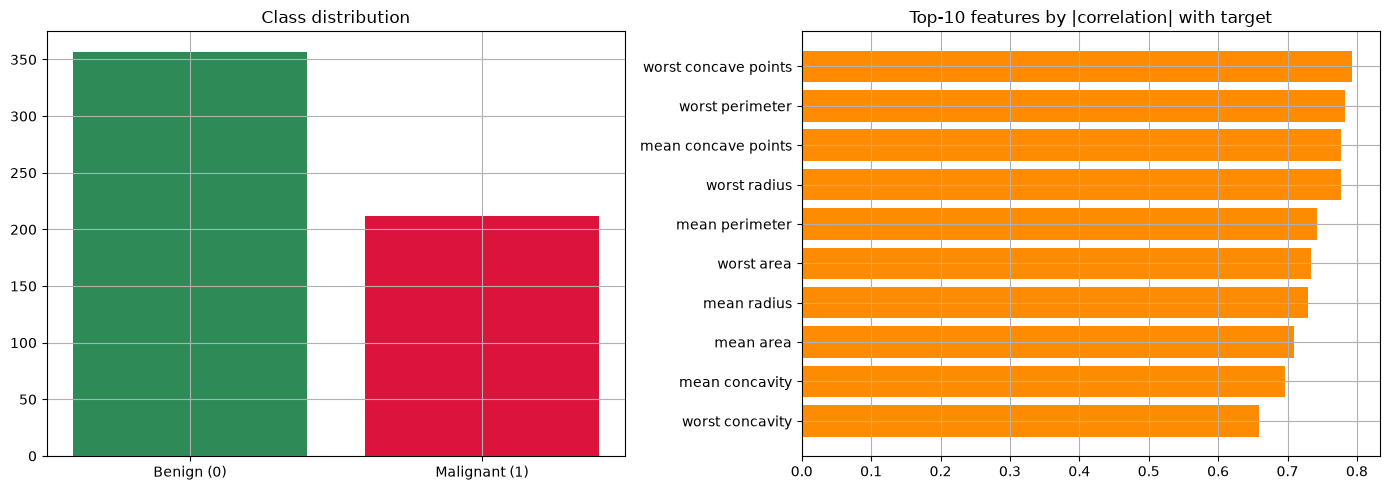

In [3]:
counts = df["target"].value_counts().sort_index()
print("Class counts:", {"Benign (0)": counts[0], "Malignant (1)": counts[1]})
print("Missing values:", df.isna().sum().sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(["Benign (0)", "Malignant (1)"], counts.values, color=["seagreen", "crimson"])
axes[0].set_title("Class distribution")
corr = df.corr()["target"].drop("target").abs().sort_values().tail(10)
axes[1].barh(corr.index, corr.values, color="darkorange")
axes[1].set_title("Top-10 features by |correlation| with target")
plt.tight_layout(); plt.show()

## 2) تجهيز الداتا

- تقسيم **80% train / 20% test** مع `stratify` حتى تبقى نسبة الكلاسين نفسها بالقسمين.
- **Standardization** (mean=0, std=1) — ضرورية للـ optimizers المبنية على الـ gradient، لأن الـ features بمقاييس مختلفة كتير (مثلاً `area` بالمئات و `smoothness` أقل من 1).
- الـ scaler بيتعلّم من الـ train بس (لتجنّب data leakage).

In [4]:
X = df.drop(columns="target").values
y = df["target"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

n_samples, n_features = X_train.shape
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Malignant ratio — train: {y_train.mean():.3f}, test: {y_test.mean():.3f}")

Train: (455, 30) | Test: (114, 30)
Malignant ratio — train: 0.374, test: 0.368


## 3) الموديل: Logistic Regression من الصفر (NumPy)

**Sigmoid** بتحوّل أي رقم لاحتمال بين 0 و 1:
$$z = Xw + b, \qquad \hat{p} = \sigma(z) = \frac{1}{1 + e^{-z}}$$

**Loss — Binary Cross-Entropy (Log Loss):**
$$L(w,b) = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i \log \hat{p}_i + (1-y_i)\log(1-\hat{p}_i)\Big]$$

**Gradients** (نفس شكل الـ Linear Regression تقريباً!):
$$\frac{\partial L}{\partial w} = \frac{1}{n}X^T(\hat{p}-y), \qquad \frac{\partial L}{\partial b} = \frac{1}{n}\sum(\hat{p}-y)$$

**التصنيف:** إذا $\hat{p} \ge 0.5$ ← الكلاس 1 (خبيث)، غير هيك ← الكلاس 0 (حميد).

In [5]:
def sigmoid(z):
    z = np.clip(z, -500, 500)               # numerical stability
    return 1 / (1 + np.exp(-z))

def predict_proba(X, w, b):
    return sigmoid(X @ w + b)

def predict(X, w, b, threshold=0.5):
    return (predict_proba(X, w, b) >= threshold).astype(int)

def bce_loss(X, y, w, b, eps=1e-12):
    p = np.clip(predict_proba(X, w, b), eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def gradients(X, y, w, b):
    n = X.shape[0]
    err = predict_proba(X, w, b) - y
    dw = (X.T @ err) / n
    db = np.sum(err) / n
    return dw, db

## 4) الـ Metrics — محسوبة من الصفر

من الـ **Confusion Matrix**:

| | Predicted 1 | Predicted 0 |
|---|---|---|
| **Actual 1** | TP | FN |
| **Actual 0** | FP | TN |

- **Accuracy** $= \dfrac{TP+TN}{TP+TN+FP+FN}$ — نسبة التوقعات الصحيحة من الكل.
- **Precision** $= \dfrac{TP}{TP+FP}$ — من اللي توقعنا إنهم خبيثين، قديش فعلاً خبيثين؟
- **Recall** $= \dfrac{TP}{TP+FN}$ — من كل الأورام الخبيثة، قديش قدرنا نكتشف؟ (الأهم طبياً)
- **F1** $= 2\cdot\dfrac{Precision \cdot Recall}{Precision + Recall}$ — التوازن بين الاتنين.
- **Loss** = Binary Cross-Entropy (فوق).

In [6]:
def confusion(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp, tn, fp, fn

def compute_metrics(X, y, w, b):
    y_pred = predict(X, w, b)
    tp, tn, fp, fn = confusion(y, y_pred)
    accuracy = (tp + tn) / len(y)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return {"Loss": bce_loss(X, y, w, b), "Accuracy": accuracy,
            "Precision": precision, "Recall": recall, "F1": f1}

## 5) Baseline: `sklearn.LogisticRegression`

موديل جاهز من sklearn (بيستخدم solver اسمه `lbfgs`) حتى نقارن فيه نتائج الـ optimizer تبعنا.

In [7]:
ref = LogisticRegression(max_iter=5000).fit(X_train, y_train)
ref_pred = ref.predict(X_test)
ref_metrics = {
    "Loss": skm.log_loss(y_test, ref.predict_proba(X_test)[:, 1]),
    "Accuracy": skm.accuracy_score(y_test, ref_pred),
    "Precision": skm.precision_score(y_test, ref_pred),
    "Recall": skm.recall_score(y_test, ref_pred),
    "F1": skm.f1_score(y_test, ref_pred),
}
pd.Series(ref_metrics, name="sklearn (test)").round(4).to_frame().T

,Loss,Accuracy,Precision,Recall,F1
sklearn (test),0.0773,0.9649,0.975,0.9286,0.9512


## 6) الـ Optimizer: SGD

**SGD** بيحسب الـ gradient على **عيّنة وحدة** بكل خطوة، فبيعمل `n` updates بكل epoch:

$$w \leftarrow w - \eta \, \nabla_w L(x_i, y_i)$$

- ✅ updates كتيرة، بيتقارب بعدد epochs قليل.
- ❌ الـ loss متذبذب (noisy)، وبطيء بالـ Python لأنه ما بيستفيد من الـ vectorization.

In [8]:
def train(lr=0.01, epochs=50):
    w = np.zeros(n_features)
    b = 0.0
    history = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}
    history["iter"] = []
    for epoch in range(epochs):
        idx = np.random.permutation(n_samples)    # shuffle every epoch
        for k, i in enumerate(idx):
            xi, yi = X_train[i], y_train[i]
            err = sigmoid(xi @ w + b) - yi        # gradient on ONE sample
            w -= lr * err * xi
            b -= lr * err
            if k % 25 == 0:
                history["iter"].append(bce_loss(X_train, y_train, w, b))
        history["train_loss"].append(bce_loss(X_train, y_train, w, b))
        history["test_loss"].append(bce_loss(X_test, y_test, w, b))
        history["train_acc"].append(np.mean(predict(X_train, w, b) == y_train))
        history["test_acc"].append(np.mean(predict(X_test, w, b) == y_test))
    return w, b, history

In [9]:
start = time.time()
w, b, history = train(lr=0.01, epochs=50)
train_time = time.time() - start

## 7) النتائج والتقييم

In [10]:
print(f"Training time: {train_time:.2f} s")

results = pd.DataFrame([
    pd.Series(compute_metrics(X_train, y_train, w, b), name="SGD (train)"),
    pd.Series(compute_metrics(X_test, y_test, w, b), name="SGD (test)"),
    pd.Series(ref_metrics, name="sklearn (test)"),
]).round(4)
results

Training time: 0.83 s


,Loss,Accuracy,Precision,Recall,F1
SGD (train),0.0526,0.9890,1.0000,0.9706,0.9851
SGD (test),0.0717,0.9737,0.9756,0.9524,0.9639
sklearn (test),0.0773,0.9649,0.9750,0.9286,0.9512


### تأكيد: الـ metrics تبعنا بتطابق دوال sklearn

In [11]:
y_pred = predict(X_test, w, b)
ours = compute_metrics(X_test, y_test, w, b)
check = pd.DataFrame({
    "Ours (from scratch)": ours,
    "sklearn.metrics": {
        "Loss": skm.log_loss(y_test, predict_proba(X_test, w, b)),
        "Accuracy": skm.accuracy_score(y_test, y_pred),
        "Precision": skm.precision_score(y_test, y_pred),
        "Recall": skm.recall_score(y_test, y_pred),
        "F1": skm.f1_score(y_test, y_pred),
    },
}).round(6)
check

,Ours (from scratch),sklearn.metrics
Loss,0.071653,0.071653
Accuracy,0.973684,0.973684
Precision,0.975610,0.975610
Recall,0.952381,0.952381
F1,0.963855,0.963855


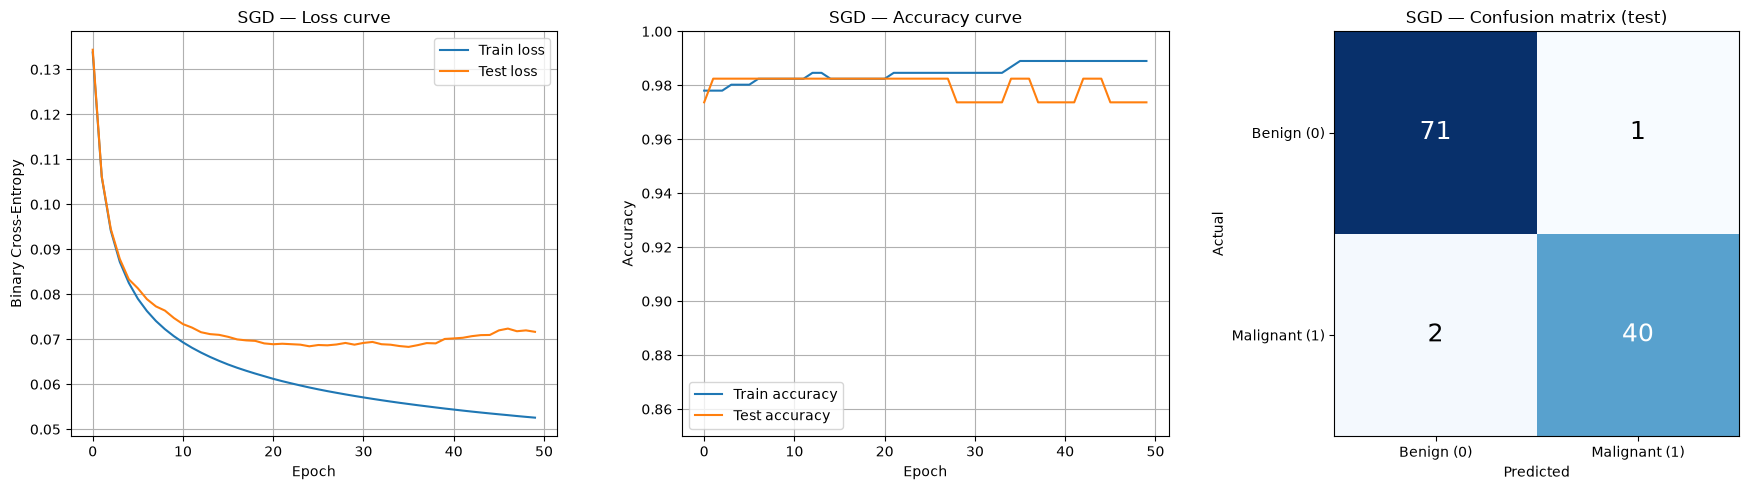

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(history["train_loss"], label="Train loss")
axes[0].plot(history["test_loss"], label="Test loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Binary Cross-Entropy")
axes[0].set_title("SGD — Loss curve"); axes[0].legend()

axes[1].plot(history["train_acc"], label="Train accuracy")
axes[1].plot(history["test_acc"], label="Test accuracy")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0.85, 1.0)
axes[1].set_title("SGD — Accuracy curve"); axes[1].legend()

tp, tn, fp, fn = confusion(y_test, predict(X_test, w, b))
cm = np.array([[tn, fp], [fn, tp]])
axes[2].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[2].text(j, i, cm[i, j], ha="center", va="center", fontsize=18,
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
axes[2].set_xticks([0, 1], ["Benign (0)", "Malignant (1)"])
axes[2].set_yticks([0, 1], ["Benign (0)", "Malignant (1)"])
axes[2].set_xlabel("Predicted"); axes[2].set_ylabel("Actual")
axes[2].set_title("SGD — Confusion matrix (test)"); axes[2].grid(False)
plt.tight_layout(); plt.show()

### الـ loss على مستوى الـ iterations (كل 25 خطوة)
هون بيبيّن التذبذب (noise) الخاص بالـ SGD:

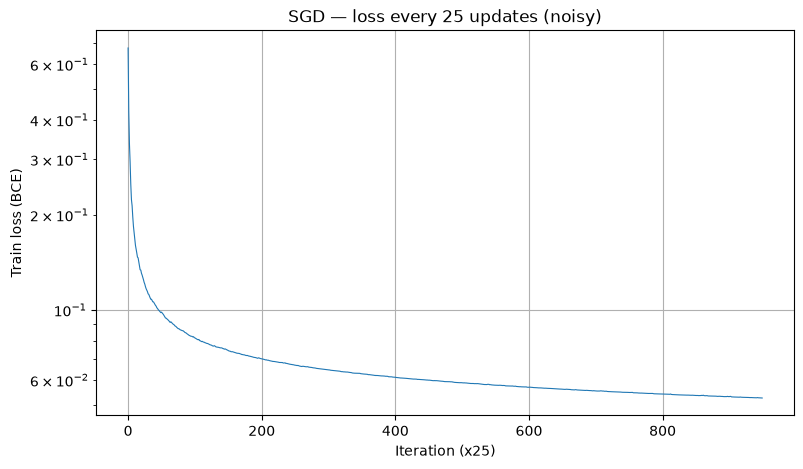

In [13]:
plt.plot(history["iter"], lw=0.8)
plt.xlabel("Iteration (x25)"); plt.ylabel("Train loss (BCE)")
plt.yscale("log"); plt.title("SGD — loss every 25 updates (noisy)"); plt.show()

## 8) تجربة: تأثير الـ Learning Rate

نفس الـ optimizer بس بقيم مختلفة للـ learning rate.

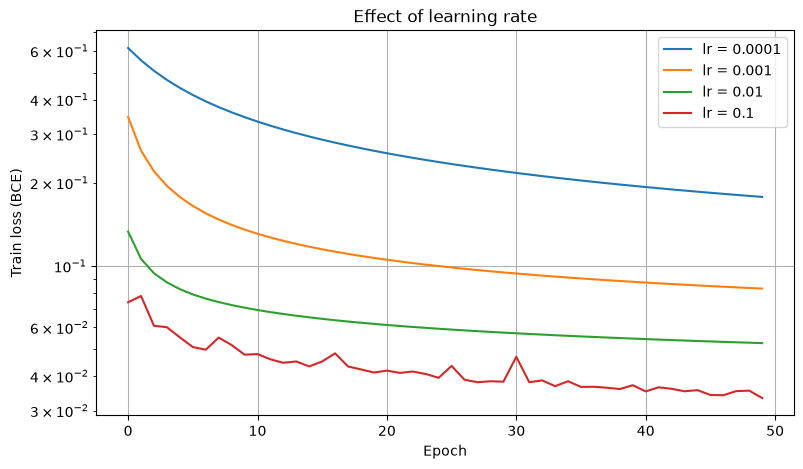

,Loss,Accuracy,Precision,Recall,F1
lr = 0.0001,0.1759,0.9649,0.9750,0.9286,0.9512
lr = 0.001,0.0841,0.9825,1.0000,0.9524,0.9756
lr = 0.01,0.0717,0.9737,0.9756,0.9524,0.9639
lr = 0.1,0.1580,0.9737,0.9756,0.9524,0.9639


In [14]:
rows = []
plt.figure(figsize=(9, 5))
for lr in [0.0001, 0.001, 0.01, 0.1]:
    w_, b_, h = train(lr=lr, epochs=50)
    plt.plot(h["train_loss"], label=f"lr = {lr}")
    rows.append(pd.Series(compute_metrics(X_test, y_test, w_, b_), name=f"lr = {lr}"))
plt.xlabel("Epoch"); plt.ylabel("Train loss (BCE)")
plt.yscale("log"); plt.title("Effect of learning rate"); plt.legend(); plt.show()
pd.DataFrame(rows).round(4)

## 9) الخلاصة

- SGD بيعمل **455 update بكل epoch** (update لكل عيّنة)، فبيوصل لـ loss منخفض خلال epochs قليلة.
- منحنى الـ loss على مستوى الـ iterations **متذبذب** لأن كل gradient من عيّنة وحدة.
- الـ learning rate الصغيرة كتير (0.0001) بطيئة، والكبيرة (0.1) بتعمل تذبذب كبير وبتكبّر الأوزان فبيطلع الـ test loss أعلى بكتير. أفضل توازن كان بين 0.001 و 0.01.